In [1]:
import numpy as np, time, urllib.request, os
from urllib.parse import quote
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow.keras import layers, models

np.random.seed(42)
tf.random.set_seed(42)
print("TF:", tf.__version__, "| GPU:", tf.config.list_physical_devices('GPU'))

TF: 2.20.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


banana (10000, 784)
hockey stick (10000, 784)
squirrel (10000, 784)
watermelon (10000, 784)
bathtub (10000, 784)
laptop (10000, 784)
rain (10000, 784)
pond (10000, 784)
nose (10000, 784)
panda (10000, 784)
Train/Val/Test: (80000, 784) (10000, 784) (10000, 784)


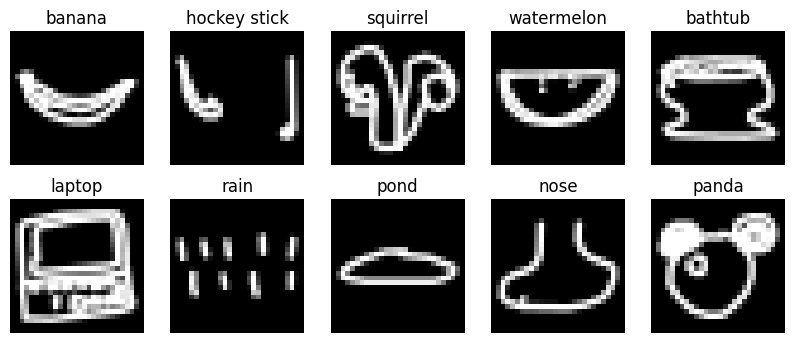

In [2]:
CLASSES = ['banana','hockey stick','squirrel','watermelon','bathtub',
           'laptop','rain','pond','nose','panda']
N_PER_CLASS = 10000
os.makedirs('data', exist_ok=True)

X_list, y_list = [], []
for idx, c in enumerate(CLASSES):
    path = f'data/{c}.npy'
    if not os.path.exists(path):
        url = f'https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/{quote(c)}.npy'
        urllib.request.urlretrieve(url, path)
    arr = np.load(path)[:N_PER_CLASS]
    X_list.append(arr)
    y_list.append(np.full(len(arr), idx))
    print(c, arr.shape)

X = np.concatenate(X_list).astype('float32') / 255.0   # (100000, 784)
y = np.concatenate(y_list)

# 80 / 10 / 10 split
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)
print("Train/Val/Test:", X_train.shape, X_val.shape, X_test.shape)

# quick visual check
fig, axs = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axs.flat):
    ax.imshow(X[i * N_PER_CLASS].reshape(28, 28), cmap='gray')
    ax.set_title(CLASSES[i]); ax.axis('off')
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LR  val acc: 0.6553 | test acc: 0.6637 | train time: 50.3s


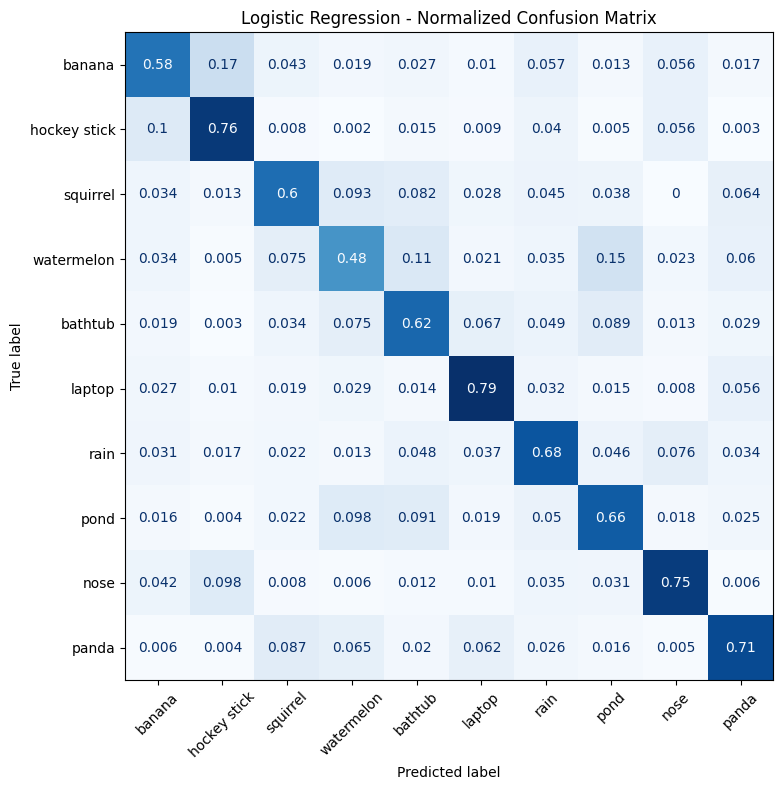

In [3]:
t0 = time.time()
lr = LogisticRegression(solver='lbfgs', max_iter=100)
lr.fit(X_train, y_train)
lr_time = time.time() - t0

lr_val_acc = accuracy_score(y_val, lr.predict(X_val))
lr_test_acc = accuracy_score(y_test, lr.predict(X_test))
print(f"LR  val acc: {lr_val_acc:.4f} | test acc: {lr_test_acc:.4f} | train time: {lr_time:.1f}s")

cm = confusion_matrix(y_test, lr.predict(X_test), normalize='true')
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, xticks_rotation=45, cmap='Blues', colorbar=False)
plt.title('Logistic Regression - Normalized Confusion Matrix')
plt.tight_layout()
plt.savefig('lr_confusion.png', dpi=150)
plt.show()

In [4]:
# reshape for CNN
Xtr = X_train.reshape(-1, 28, 28, 1)
Xva = X_val.reshape(-1, 28, 28, 1)
Xte = X_test.reshape(-1, 28, 28, 1)
NUM_CLASSES = len(CLASSES)
EPOCHS = 15

def build_cnn(version):
    m = models.Sequential([layers.Input((28, 28, 1))])
    if version == 'V1':      # 2 conv + 2 maxpool (full)
        m.add(layers.Conv2D(32, 3, padding='same', activation='relu'))
        m.add(layers.MaxPooling2D())
        m.add(layers.Conv2D(64, 3, padding='same', activation='relu'))
        m.add(layers.MaxPooling2D())
    elif version == 'V2':    # remove 2nd conv (+ its pool)
        m.add(layers.Conv2D(32, 3, padding='same', activation='relu'))
        m.add(layers.MaxPooling2D())
    elif version == 'V3':    # also remove the maxpool
        m.add(layers.Conv2D(32, 3, padding='same', activation='relu'))
    m.add(layers.Flatten())
    m.add(layers.Dense(128, activation='relu'))
    m.add(layers.Dense(NUM_CLASSES, activation='softmax'))
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

results, histories, trained = {}, {}, {}
for v in ['V1', 'V2', 'V3']:
    print(f"\n===== Training CNN {v} =====")
    model = build_cnn(v)
    print("Params:", model.count_params())
    t0 = time.time()
    h = model.fit(Xtr, y_train, validation_data=(Xva, y_val),
                  epochs=EPOCHS, batch_size=128, verbose=2)
    t = time.time() - t0
    val_acc = model.evaluate(Xva, y_val, verbose=0)[1]
    test_acc = model.evaluate(Xte, y_test, verbose=0)[1]
    results[v] = dict(val=val_acc, test=test_acc, time=t, params=model.count_params())
    histories[v], trained[v] = h.history, model
    print(f"{v}: val={val_acc:.4f} test={test_acc:.4f} time={t:.1f}s")


===== Training CNN V1 =====
Params: 421642
Epoch 1/15
625/625 - 9s - 14ms/step - accuracy: 0.7989 - loss: 0.6470 - val_accuracy: 0.8578 - val_loss: 0.4557
Epoch 2/15
625/625 - 3s - 5ms/step - accuracy: 0.8781 - loss: 0.3936 - val_accuracy: 0.8781 - val_loss: 0.3820
Epoch 3/15
625/625 - 3s - 5ms/step - accuracy: 0.8971 - loss: 0.3285 - val_accuracy: 0.8834 - val_loss: 0.3630
Epoch 4/15
625/625 - 3s - 5ms/step - accuracy: 0.9095 - loss: 0.2876 - val_accuracy: 0.8906 - val_loss: 0.3468
Epoch 5/15
625/625 - 3s - 5ms/step - accuracy: 0.9193 - loss: 0.2554 - val_accuracy: 0.8936 - val_loss: 0.3388
Epoch 6/15
625/625 - 3s - 5ms/step - accuracy: 0.9289 - loss: 0.2265 - val_accuracy: 0.8940 - val_loss: 0.3419
Epoch 7/15
625/625 - 3s - 5ms/step - accuracy: 0.9368 - loss: 0.1998 - val_accuracy: 0.8925 - val_loss: 0.3504
Epoch 8/15
625/625 - 3s - 5ms/step - accuracy: 0.9440 - loss: 0.1753 - val_accuracy: 0.8901 - val_loss: 0.3699
Epoch 9/15
625/625 - 3s - 5ms/step - accuracy: 0.9506 - loss: 0.152

Model       Val%   Test%   Time(s)      Params
LR         65.53   66.37      50.3           -
V1         87.91   87.90      55.1      421642
V2         87.07   87.43      38.5      804554
V3         85.91   86.05      43.1     3213002

Best CNN: V1


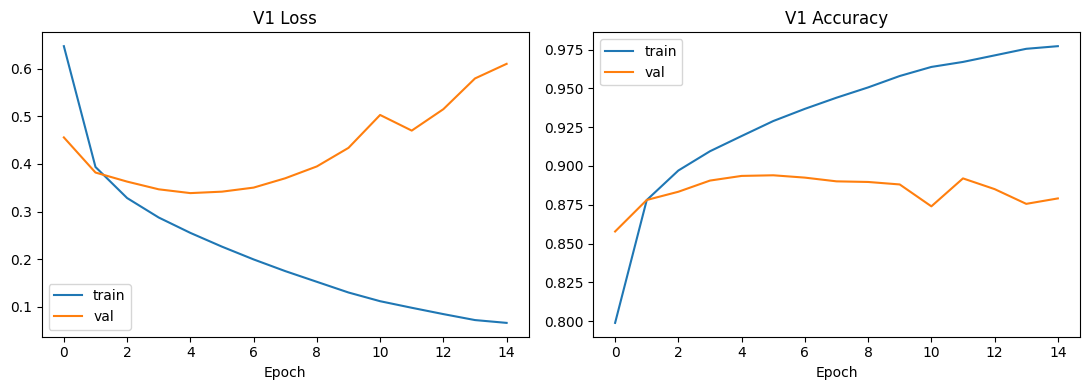

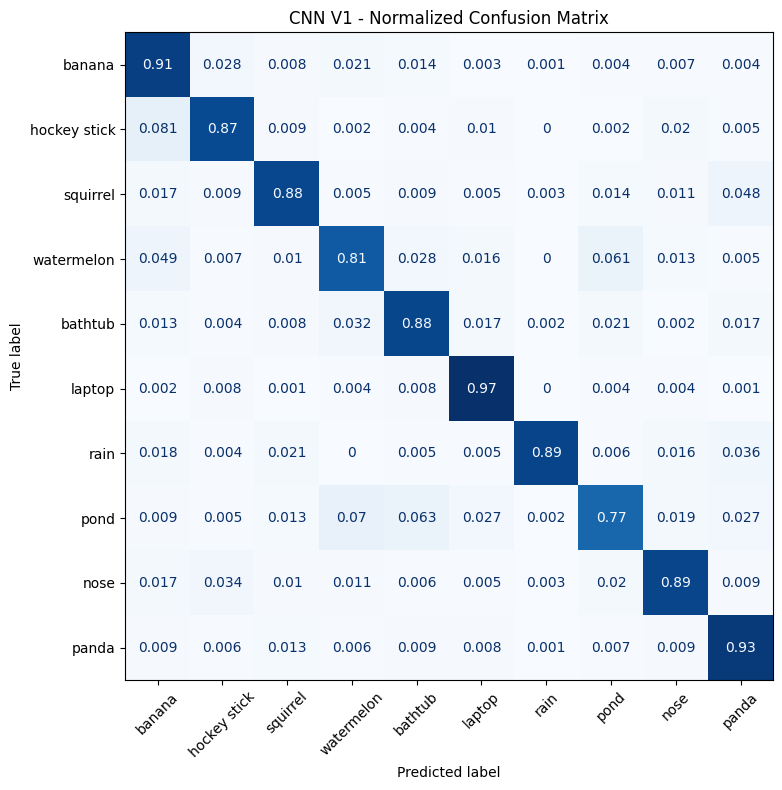

Saved best_model.keras


In [5]:
# results table
print(f"{'Model':<8}{'Val%':>8}{'Test%':>8}{'Time(s)':>10}{'Params':>12}")
print(f"{'LR':<8}{lr_val_acc*100:>8.2f}{lr_test_acc*100:>8.2f}{lr_time:>10.1f}{'-':>12}")
for v, r in results.items():
    print(f"{v:<8}{r['val']*100:>8.2f}{r['test']*100:>8.2f}{r['time']:>10.1f}{r['params']:>12}")

best = max(results, key=lambda k: results[k]['val'])
print("\nBest CNN:", best)

# training curves for best
h = histories[best]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h['loss'], label='train'); ax[0].plot(h['val_loss'], label='val')
ax[0].set_title(f'{best} Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot(h['accuracy'], label='train'); ax[1].plot(h['val_accuracy'], label='val')
ax[1].set_title(f'{best} Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout(); plt.savefig('cnn_curves.png', dpi=150); plt.show()

# confusion matrix for best
pred = trained[best].predict(Xte, verbose=0).argmax(1)
cm = confusion_matrix(y_test, pred, normalize='true')
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, xticks_rotation=45, cmap='Blues', colorbar=False)
plt.title(f'CNN {best} - Normalized Confusion Matrix')
plt.tight_layout(); plt.savefig('cnn_confusion.png', dpi=150); plt.show()

# save model
trained[best].save('best_model.keras')
print("Saved best_model.keras")

In [6]:
from google.colab import files
for f in ['best_model.keras', 'cnn_curves.png', 'cnn_confusion.png', 'lr_confusion.png']:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>